# 📝 Customer Feedback Analysis & GenAI Response Automation

## 📌 Project Introduction

Customer reviews contain valuable information about product quality, customer experience, and recurring areas of dissatisfaction. This project develops a Python-based workflow to analyze customer feedback from the **Women's Clothing E-Commerce Reviews** dataset and identify reviews requiring focused attention.

The analysis combines **Pandas-based data wrangling, transparent rule-based review analysis, frequency-based complaint keyword analysis, and Generative AI** to move from raw customer feedback to personalized customer-support responses.

### 🎯 Project Objective

The primary objectives are to:

* Clean and prepare the customer review data while preserving useful feedback.
* Identify **critical reviews rated 1 or 2 stars** using transparent rule-based logic.
* Identify recurring complaint-related keywords and themes within critical reviews.
* Select three detailed and highly relevant critical reviews using a transparent screening and manual-selection process.
* Generate personalized, empathetic customer-support emails for the selected reviews using **Gemini 3.5 Flash-Lite**.
* Validate the generated responses for relevance, personalization, factual grounding, and appropriate customer-support tone.

### 🔄 Overall Workflow

**Raw Review Data → Data Wrangling → Critical Review Identification → Complaint Keyword Analysis → Selection of 3 Critical Reviews → GenAI-Powered Customer Responses**

The workflow intentionally uses simple, explainable techniques for the core analysis and avoids machine learning for critical-review identification, in line with the assessment requirements.


# Phase 1 - Understanding the Dataset

This phase establishes the dataset structure and identifies key data-quality issues before cleaning. The analysis focuses on dataset structure, missing values, and whether missing information can be reliably recovered from the available data.


In [3]:
# ============================================================
# CORE LIBRARIES
# ============================================================

import pandas as pd                     # DataFrame manipulation, CSV I/O, groupby/agg operations
import numpy as np                      # Numerical operations, NaN handling, array math

# Visualization stack
import matplotlib.pyplot as plt         # Base plotting engine (static charts)

# Utility
import warnings                         # Control visibility of non-critical warnings

# Display settings
pd.set_option('display.max_columns', None)    # Show all columns when printing DataFrames (no truncation)
pd.set_option('display.width', 150)           # Widen console/output width to avoid wrapped columns
pd.set_option('display.max_colwidth', 100)    # Prevent long text fields (e.g., description) from truncating

In [4]:
# ============================================================
# WARNING MANAGEMENT
# ============================================================
# We suppress ONLY cosmetic/non-actionable warnings (e.g., future deprecation
# notices from libraries) — NOT all warnings. Blanket suppression is a bad
# practice because it can hide genuine data issues (e.g., dtype coercion
# warnings, SettingWithCopyWarning) that we actually want to see during EDA.

warnings.filterwarnings('ignore', category=FutureWarning)                  # Library API changes

# NOTE: We deliberately do NOT suppress:
# - SettingWithCopyWarning (tells us if we're accidentally modifying a view vs a copy)
# - DtypeWarning (tells us if pandas silently mixed types while reading a column)

In [5]:
# ============================================================
# DATA LOADING
# ============================================================

# Path to the dataset; adjust if the CSV is not in the same folder as your notebook
DATA_PATH = r"D:\c\rudresh\rudresh datascience\backup pc\Data Science\Coursework\imarticus internship\Womens Clothing E-Commerce Reviews.csv"

df = pd.read_csv(DATA_PATH)  # load the CSV with default settings

print(f"✅ Dataset loaded successfully from '{DATA_PATH}'")
print("Dataset shape (rows, columns):", df.shape)

✅ Dataset loaded successfully from 'D:\c\rudresh\rudresh datascience\backup pc\Data Science\Coursework\imarticus internship\Womens Clothing E-Commerce Reviews.csv'
Dataset shape (rows, columns): (23486, 11)


In [6]:
# ============================================================
# STRUCTURAL OVERVIEW
# ============================================================

print("Column names:")
print(list(df.columns))

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Column names:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

Data types:
Unnamed: 0                  int64
Clothing ID                 int64
Age                         int64
Title                      object
Review Text                object
Rating                      int64
Recommended IND             int64
Positive Feedback Count     int64
Division Name              object
Department Name            object
Class Name                 object
dtype: object

First 5 rows:


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i n...",5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered th...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get no...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length t...,5,1,6,General,Tops,Blouses


In [7]:
# ============================================================
# MISSING VALUE ANALYSIS
# ============================================================

missing_counts = df.isna().sum()  # count of missing values per column

missing_summary = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing %": (missing_counts / len(df) * 100).round(2)
}).sort_values("Missing Count", ascending=False)

display(missing_summary)

,Missing Count,Missing %
Title,3810,16.22
Review Text,845,3.60
Division Name,14,0.06
Department Name,14,0.06
Class Name,14,0.06
Unnamed: 0,0,0.00
Clothing ID,0,0.00
Age,0,0.00
Rating,0,0.00
Recommended IND,0,0.00


In [8]:
# ============================================================
# Review Text Missingness
# ============================================================

missing_text = df["Review Text"].isna()

print("1. Records with missing Review Text:", missing_text.sum())
print("2. Of these, records with a non-missing Title:", df.loc[missing_text, "Title"].notna().sum())
print("3. Of these, records rated 1 or 2 stars:", df.loc[missing_text, "Rating"].isin([1, 2]).sum())

print("\n4. Record(s) with missing Review Text but available Title:")
display(df.loc[missing_text & df["Title"].notna(), ["Rating", "Title", "Review Text"]].head(5))

1. Records with missing Review Text: 845
2. Of these, records with a non-missing Title: 1
3. Of these, records rated 1 or 2 stars: 37

4. Record(s) with missing Review Text but available Title:


,Rating,Title,Review Text
10220,5,Such a beautiful dress!,NaN


In [9]:
# ============================================================
# Detailed Missing Value Patterns
# ============================================================

# --- A. Title and Review Text combinations ---

title_present = df["Title"].notna()
text_present = df["Review Text"].notna()

group_counts = pd.Series({
    "Title present + Review Text present": (title_present & text_present).sum(),
    "Title present + Review Text missing": (title_present & ~text_present).sum(),
    "Title missing + Review Text present": (~title_present & text_present).sum(),
    "Title missing + Review Text missing": (~title_present & ~text_present).sum(),
})
print("A. Title / Review Text group counts:")
display(group_counts)

group2_mask = title_present & ~text_present
group4_mask = ~title_present & ~text_present

print("\nGroup 2 (Title present, Review Text missing) - Rating distribution:")
display(df.loc[group2_mask, "Rating"].value_counts().sort_index())

print("\nGroup 4 (Title missing, Review Text missing) - Rating distribution:")
display(df.loc[group4_mask, "Rating"].value_counts().sort_index())

print("\nGroup 2 - all records:")
display(df.loc[group2_mask, ["Rating", "Title", "Review Text"]])

# --- B. Category fields ---

cat_cols = ["Division Name", "Department Name", "Class Name"]

print("\nB. Missing counts per category column:")
display(df[cat_cols].isna().sum())

all_missing_mask = df[cat_cols].isna().all(axis=1)
print("\nRecords missing all three category fields:", all_missing_mask.sum())

print("\nRelevant rows:")
display(df.loc[all_missing_mask, ["Clothing ID", "Division Name", "Department Name", "Class Name", "Rating", "Review Text"]])

A. Title / Review Text group counts:


Title present + Review Text present    19675
Title present + Review Text missing        1
Title missing + Review Text present     2966
Title missing + Review Text missing      844
dtype: int64


Group 2 (Title present, Review Text missing) - Rating distribution:


Rating
5    1
Name: count, dtype: int64


Group 4 (Title missing, Review Text missing) - Rating distribution:


...

,Rating,Title,Review Text
10220,5,Such a beautiful dress!,NaN



B. Missing counts per category column:


Division Name      14
Department Name    14
Class Name         14
dtype: int64


Records missing all three category fields: 14

Relevant rows:


,Clothing ID,Division Name,Department Name,Class Name,Rating,Review Text
9444,72,NaN,NaN,NaN,5,"I never write reviews, but these socks are so worth it! they are incredibly soft, stretchy, and ..."
13767,492,NaN,NaN,NaN,5,I just love this hoodie! it is so soft and comfortable. i am usually an extra small and that siz...
13768,492,NaN,NaN,NaN,5,Love this hoodie. so soft and goes with everything. highly recommend for comfort and style. grea...
13787,492,NaN,NaN,NaN,5,NaN
16216,152,NaN,NaN,NaN,5,"Just what i was looking for. soft, cozy and warm."
16221,152,NaN,NaN,NaN,5,I am loving these. they are quite long but are prefect to wear with pj shorts or leggings. very ...
16223,152,NaN,NaN,NaN,5,These leg warmers are perfect for me. they are long enough and thick and warm enough to keep me ...
18626,184,NaN,NaN,NaN,5,"These are amazing quality. i agree, size up to not have such a sheer effect. i would not wear th..."
18671,184,NaN,NaN,NaN,5,"These tights are amazing! if i care for them well, i know they will last me seasons upon seasons."
20088,772,NaN,NaN,NaN,5,This sweatshirt is really nice! it's oversized so best worn with leggings or skinny jeans. it's...


In [10]:
# ============================================================
# Category Metadata Recoverability
# ============================================================

cat_cols = ["Division Name", "Department Name", "Class Name"]

# The 14 records with all three category fields missing
missing_all_mask = df[cat_cols].isna().all(axis=1)
missing_ids = df.loc[missing_all_mask, "Clothing ID"].unique()

# For each of those Clothing IDs, look at other records with the same ID
# where the category fields ARE present, and see what combination(s) they show
recovery_rows = []
for cid in missing_ids:
    matches = df[(df["Clothing ID"] == cid) & df[cat_cols].notna().all(axis=1)]
    combos = matches[cat_cols].drop_duplicates()
    for _, combo in combos.iterrows():
        count = (
            (matches["Division Name"] == combo["Division Name"])
            & (matches["Department Name"] == combo["Department Name"])
            & (matches["Class Name"] == combo["Class Name"])
        ).sum()
        recovery_rows.append({
            "Clothing ID": cid,
            "Division Name": combo["Division Name"],
            "Department Name": combo["Department Name"],
            "Class Name": combo["Class Name"],
            "Matching Records": count,
        })

recovery_df = pd.DataFrame(recovery_rows)
if recovery_df.empty:
    print("No matching records with complete category information were found for these Clothing IDs.")
else:
    display(recovery_df)

No matching records with complete category information were found for these Clothing IDs.


In [11]:
# ============================================================
# Category Metadata Validation
# ============================================================

cat_cols = ["Division Name", "Department Name", "Class Name"]

missing_all_mask = df[cat_cols].isna().all(axis=1)
missing_ids = df.loc[missing_all_mask, "Clothing ID"].unique()

print("1. Unique Clothing IDs among the 14 records:")
print(missing_ids)

print("\n2 & 3. For each Clothing ID, total records and category-field availability:")
for cid in missing_ids:
    subset = df[df["Clothing ID"] == cid]
    print(f"\nClothing ID {cid}: {len(subset)} total records")
    display(subset[cat_cols].notna().rename(columns=lambda c: f"{c} present"))

1. Unique Clothing IDs among the 14 records:
[ 72 492 152 184 772 665 136]

2 & 3. For each Clothing ID, total records and category-field availability:

Clothing ID 72: 1 total records


,Division Name present,Department Name present,Class Name present
9444,False,False,False



Clothing ID 492: 3 total records


,Division Name present,Department Name present,Class Name present
13767,False,False,False
13768,False,False,False
13787,False,False,False



Clothing ID 152: 3 total records


...

,Division Name present,Department Name present,Class Name present
20088,False,False,False



Clothing ID 665: 1 total records


,Division Name present,Department Name present,Class Name present
21532,False,False,False



Clothing ID 136: 3 total records


,Division Name present,Department Name present,Class Name present
22997,False,False,False
23006,False,False,False
23011,False,False,False


### Phase 1 Summary

The dataset contains **23,486 reviews across 11 columns**. `Title` and `Review Text` provide the primary customer feedback, while `Rating`, `Recommended IND`, and product-category fields provide supporting context.

The main data-quality issues identified were:

* `Title`: 3,810 missing values
* `Review Text`: 845 missing values
* Category fields: 14 records missing `Division Name`, `Department Name`, and `Class Name` together

Among the records without `Review Text`, **1 has a usable Title**, while **844 have neither Title nor Review Text**. The category investigation also showed that the missing category values cannot be reliably recovered from other records with the same `Clothing ID`.

These findings establish the data-quality considerations that will guide the cleaning and preparation steps in **Phase 2**.


# Phase 2 - Data Wrangling & Text Cleaning

This phase prepares the dataset for analysis by addressing the data-quality issues identified in Phase 1. The process includes handling missing feedback, cleaning review text and titles, checking for duplicates and blank text, standardizing selected fields, and validating the final analysis-ready dataset.


In [12]:
# ============================================================
# Handle Missing Feedback Records
# ============================================================

# 1. Use the existing row-index column as the DataFrame index, renamed to Review ID
df = df.set_index("Unnamed: 0")
df.index.name = "Review ID"

# 2. Fill the single record where Review Text is missing but Title is present
title_present = df["Title"].notna()
text_missing = df["Review Text"].isna()
single_fill_mask = title_present & text_missing
df.loc[single_fill_mask, "Review Text"] = df.loc[single_fill_mask, "Title"]

# 3. Drop the records where both Title and Review Text are missing
both_missing_mask = df["Title"].isna() & df["Review Text"].isna()
df = df[~both_missing_mask]

# --- Checks ---
print("Shape:", df.shape)
print("Missing Review Text:", df["Review Text"].isna().sum())
print("Missing Title:", df["Title"].isna().sum())

cat_cols = ["Division Name", "Department Name", "Class Name"]
print("\nMissing values per category column:")
display(df[cat_cols].isna().sum())

print("\nColumn names:", list(df.columns))
print("Index name:", df.index.name)

Shape: (22642, 10)
Missing Review Text: 0
Missing Title: 2966

Missing values per category column:


Division Name      13
Department Name    13
Class Name         13
dtype: int64


Column names: ['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']
Index name: Review ID


In [13]:
# ============================================================
# Review Text Cleaning
# ============================================================

# Text cleaning: lowercase + whitespace normalization only (punctuation preserved)
sample_idx = df["Review Text"].sample(5, random_state=42).index

print("BEFORE cleaning:")
display(df.loc[sample_idx, "Review Text"])

df["Review Text"] = (
    df["Review Text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("\nAFTER cleaning:")
display(df.loc[sample_idx, "Review Text"])

BEFORE cleaning:


Review ID
19566    This dress is beautiful with gorgeous coloring, nice thick, stretchy fabric and wonderful detail...
17836                                         Super flattering, a great length for me (5'9") but very sheer.
9304     I've been searching for the perfect gray cardigan and i knew i had to have this one! unfortunate...
4587                         The sales girl added this to my room, it's so darling and it came home with me.
14858    I bought the delaney blazer in size 6 -- and i really like it. there are surprising design eleme...
Name: Review Text, dtype: object


AFTER cleaning:


Review ID
19566    this dress is beautiful with gorgeous coloring, nice thick, stretchy fabric and wonderful detail...
17836                                         super flattering, a great length for me (5'9") but very sheer.
9304     i've been searching for the perfect gray cardigan and i knew i had to have this one! unfortunate...
4587                         the sales girl added this to my room, it's so darling and it came home with me.
14858    i bought the delaney blazer in size 6 -- and i really like it. there are surprising design eleme...
Name: Review Text, dtype: object

In [14]:
# ============================================================
# Duplicate and Blank Text Checks
# ============================================================

# 1. Exact duplicate records across all columns (Review ID index excluded automatically)
dup_mask = df.duplicated(keep=False)
print("Number of exact duplicate rows (all occurrences):", dup_mask.sum())

if dup_mask.sum() > 0:
    print("\nSample of duplicate records:")
    display(df[dup_mask].sort_values(list(df.columns)).head(10))
    print("\nDuplicated row count (excluding first occurrence):", df.duplicated(keep="first").sum())

# 2. Blank or whitespace-only Review Text values
blank_text_count = (df["Review Text"].str.strip() == "").sum()
print("\nBlank/whitespace-only Review Text values:", blank_text_count)

Number of exact duplicate rows (all occurrences): 2

Sample of duplicate records:


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
Review ID,,,,,,,,,,
9447,1022,37,NaN,"love, love these jeans. being short they come right to my ankle. super soft and don?t require an...",5,1,0,General,Bottoms,Jeans
21888,1022,37,NaN,"love, love these jeans. being short they come right to my ankle. super soft and don?t require an...",5,1,0,General,Bottoms,Jeans



Duplicated row count (excluding first occurrence): 1

Blank/whitespace-only Review Text values: 0


In [15]:
# ============================================================
# Standardize Fields and Complete Data Cleaning
# ============================================================

# 1. Remove exact duplicates (comparing all columns except the Review ID index)
df = df[~df.duplicated(keep="first")]

# 2. Complete missing Titles using the first 5 words of Review Text
missing_title_mask = df["Title"].isna()

def derive_title(text):
    words = text.split()
    if len(words) > 5:
        return " ".join(words[:5]) + "..."
    return " ".join(words)

df.loc[missing_title_mask, "Title"] = df.loc[missing_title_mask, "Review Text"].apply(derive_title)

# 3. Convert Recommended IND -> Product Recommended (Yes/No)
df["Product Recommended"] = df["Recommended IND"].map({1: "Yes", 0: "No"})
df = df.drop(columns="Recommended IND")

# 4. Remove the 13 records missing all three category fields
cat_cols = ["Division Name", "Department Name", "Class Name"]
df = df[~df[cat_cols].isna().all(axis=1)]

# 5. Reorder columns
column_order = [
    "Clothing ID", "Age", "Title", "Review Text", "Rating",
    "Product Recommended", "Positive Feedback Count",
    "Division Name", "Department Name", "Class Name",
]
df = df[column_order]

# Examples of derived titles (using the mask captured before filling)
print("\nExamples of derived Titles:")
display(df.loc[missing_title_mask, ["Title", "Review Text"]].head(5))


Examples of derived Titles:


,Title,Review Text
Review ID,,
0,absolutely wonderful - silky and...,absolutely wonderful - silky and sexy and comfortable
1,love this dress! it's sooo...,"love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i nev..."
11,this dress is perfection! so...,this dress is perfection! so pretty and flattering.
30,beautifully made pants and on...,beautifully made pants and on trend with the flared crop. so much cuter in person. love these!
36,this is a comfortable skirt...,"this is a comfortable skirt that can span seasons easily. while not the most exciting design, it..."


In [16]:
# ============================================================
# Title Cleaning
# ============================================================

# Ensure df is an independent copy to avoid SettingWithCopyWarning on further assignments
df = df.copy()

# Clean Title column: lowercase, normalize whitespace, strip - punctuation preserved
df["Title"] = (
    df["Title"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# --- Checks ---
print("Sample Titles and corresponding Review Text:")
display(df[["Title", "Review Text"]].sample(5, random_state=42))

print("\nMissing Title values:", df["Title"].isna().sum())
print("Missing Review Text values:", df["Review Text"].isna().sum())
print("\nFinal shape:", df.shape)

Sample Titles and corresponding Review Text:


,Title,Review Text
Review ID,,
8329,change armpits,"i love, love this dress except for the armpits. if they had just made the armpits a normal round..."
17942,runs a tad big but...,runs a tad big but not enough to say it runs large if that makes sense - but just beautiful!
2157,best. tee. ever.,oh my! i love this tee. it is super soft. i love how it doesn't look like a sack with no shape. ...
11455,basic black t,"i got this in black and it's a great basic t-shirt- the v-neck is just right in depth, and the m..."
14385,pretty in pink,"beautiful color. emphasizes a small waist; top is fitted, so if you're curvy, beware. i'm a 32 d..."



Missing Title values: 0
Missing Review Text values: 0

Final shape: (22628, 10)


In [17]:
# ============================================================
# Final Validation and Analysis-Ready Dataset
# ============================================================

# --- Validation checks on current df ---

print("1. Shape:", df.shape)

print("\n2. Missing values per column:")
display(df.isna().sum())

print("\n3. Blank/whitespace-only values:")
print("Title:", (df["Title"].str.strip() == "").sum())
print("Review Text:", (df["Review Text"].str.strip() == "").sum())

print("\n4. Exact duplicate rows:", df.duplicated().sum())

print("\n5. Unique values in Product Recommended:")
display(df["Product Recommended"].unique())

print("\n6. Column names and order:", df.columns.tolist())

print("\n7. Index name:", df.index.name)

# --- If all checks above are clean, create the analysis-ready checkpoint ---
df_analysis = df.copy()

print("\ndf_analysis shape:", df_analysis.shape)
print("\ndf_analysis missing values:")
display(df_analysis.isna().sum())
print("\ndf_analysis index name:", df_analysis.index.name)
print("\ndf_analysis columns:", df_analysis.columns.tolist())
print("\ndf_analysis Product Recommended value counts:")
display(df_analysis["Product Recommended"].value_counts())

1. Shape: (22628, 10)

2. Missing values per column:


Clothing ID                0
Age                        0
Title                      0
Review Text                0
Rating                     0
Product Recommended        0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
dtype: int64


3. Blank/whitespace-only values:
Title: 0
Review Text: 0

4. Exact duplicate rows: 0

5. Unique values in Product Recommended:


array(['Yes', 'No'], dtype=object)


6. Column names and order: ['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Product Recommended', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

7. Index name: Review ID

df_analysis shape: (22628, 10)

df_analysis missing values:


Clothing ID                0
Age                        0
Title                      0
Review Text                0
Rating                     0
Product Recommended        0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
dtype: int64


df_analysis index name: Review ID

df_analysis columns: ['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Product Recommended', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

df_analysis Product Recommended value counts:


Product Recommended
Yes    18527
No      4101
Name: count, dtype: int64

### Phase 2 Summary

The dataset was cleaned and standardized based on the data-quality issues identified in Phase 1. The cleaning process focused on preserving usable customer feedback, removing records that could not contribute meaningful review information, standardizing text fields, and validating the resulting dataset before analysis.

The following treatments were applied:

* The original row identifier was retained as the **`Review ID`** index to preserve record-level traceability.
* The **1 record** with missing `Review Text` but an available `Title` was recovered by using the Title as the review text.
* The **844 records** with neither `Title` nor `Review Text` were removed because no customer feedback was available for analysis.
* `Review Text` was standardized by converting it to lowercase, normalizing whitespace, and removing leading/trailing whitespace. **Punctuation was preserved** to retain potentially useful textual information.
* Exact duplicate records were checked after text cleaning. **1 duplicate occurrence was removed**, leaving no exact duplicate analytical records.
* Missing `Title` values were completed using the first five words of the corresponding `Review Text`, with an ellipsis added when the review contained more than five words.
* `Recommended IND` was converted into the more readable **`Product Recommended`** field with `Yes` and `No` values.
* The **13 records** with missing `Division Name`, `Department Name`, and `Class Name` were removed because the Phase 1 investigation found that their category information could not be reliably recovered from other records with the same `Clothing ID`.
* The final columns were reordered to provide a consistent structure for subsequent analysis.

After cleaning, the analysis-ready dataset **`df_analysis` contains 22,628 reviews across 10 analytical columns**. All retained records have non-missing values in the final analytical fields, contain no blank or whitespace-only `Title` or `Review Text` values, and contain no exact duplicate records.

The resulting `df_analysis` serves as the **analysis-ready baseline** for the remaining phases. Subsequent analysis will use this cleaned dataset rather than the original raw data.


# Phase 3 - Rule Based Critical Review Analysis

This phase identifies critical customer reviews using a transparent, rule-based approach based solely on star rating. Reviews rated **1 or 2 stars** are classified as critical and separated from the analysis-ready dataset for focused analysis.

No machine learning, sentiment analysis, or additional scoring is used to determine criticality. This ensures that the classification remains simple, reproducible, and directly aligned with the assessment requirements.


In [18]:
# ============================================================
# Define and Extract Critical Reviews
# ============================================================

def get_critical_reviews(data):
    """Return only reviews with a Rating of 1 or 2 (rule-based definition of 'Critical')."""
    return data[data["Rating"].isin([1, 2])]

critical_reviews = get_critical_reviews(df_analysis)
print("critical_reviews shape:", critical_reviews.shape)

critical_reviews shape: (2370, 10)


In [19]:
# ============================================================
# Critical Review Overview
# ============================================================

total_reviews = len(df_analysis)
total_critical = len(critical_reviews)
one_star = (critical_reviews["Rating"] == 1).sum()
two_star = (critical_reviews["Rating"] == 2).sum()
critical_pct = (total_critical / total_reviews) * 100

print("Total reviews in df_analysis:", total_reviews)
print("Total critical reviews:", total_critical)
print("1-star critical reviews:", one_star)
print("2-star critical reviews:", two_star)
print(f"Percentage of all reviews that are critical: {critical_pct:.2f}%")

print("\nRating distribution within critical_reviews:")
display(critical_reviews["Rating"].value_counts().sort_index())

Total reviews in df_analysis: 22628
Total critical reviews: 2370
1-star critical reviews: 821
2-star critical reviews: 1549
Percentage of all reviews that are critical: 10.47%

Rating distribution within critical_reviews:


Rating
1     821
2    1549
Name: count, dtype: int64

In [20]:
# ============================================================
# Rule Validation and Sample of Critical Reviews
# ============================================================

print("Unique Rating values in critical_reviews:", sorted(critical_reviews["Rating"].unique()))
print("Minimum Rating:", critical_reviews["Rating"].min())
print("Maximum Rating:", critical_reviews["Rating"].max())

print("\nAny ratings outside {1, 2}?", not critical_reviews["Rating"].isin([1, 2]).all())
print("Both 1-star and 2-star present?", set(critical_reviews["Rating"].unique()) == {1, 2})

print("\nSample critical reviews:")
display(critical_reviews[["Rating", "Title", "Review Text"]].sample(5, random_state=42))

Unique Rating values in critical_reviews: [np.int64(1), np.int64(2)]
Minimum Rating: 1
Maximum Rating: 2

Any ratings outside {1, 2}? False
Both 1-star and 2-star present? True

Sample critical reviews:


,Rating,Title,Review Text
Review ID,,,
10858,2,this nightgown looked so comfy...,this nightgown looked so comfy and cute! i ordered a large and it was so uncomfortably tight.i'm...
1809,1,"droopy front, heavy fabric","right out of the bag, this top didn't really match the one pictured here (it is the right top, t..."
18036,1,dress just did not fit...,dress just did not fit will around the hips. also the string belt was defective - basically abou...
7435,2,if you want a crop top...,i love everything about this except the length. i am short and usually order a petite and even t...
7146,2,should have believed the negative reviews,"like most people here, i wanted this beautiful dress to fit. so, i decided to see for myself if ..."


In [21]:
# ============================================================
# Product Recommendation Among Critical Reviews
# ============================================================

# Count and percentage of Product Recommended within critical_reviews
recommend_counts = critical_reviews["Product Recommended"].value_counts()
recommend_pct = (critical_reviews["Product Recommended"].value_counts(normalize=True) * 100).round(2)

recommend_summary = pd.DataFrame({
    "Count": recommend_counts,
    "Percentage": recommend_pct
})

print("Product Recommended within critical_reviews:")
display(recommend_summary)


Product Recommended within critical_reviews:


,Count,Percentage
Product Recommended,,
No,2261,95.4
Yes,109,4.6


### Interpretation of Product Recommendation

Among the **2,370 critical reviews**, **2,261 customers (95.4%)** marked the product as not recommended, while **109 customers (4.6%)** still marked it as recommended.

This indicates that a critical star rating and the customer's recommendation decision are not identical measures. While most critical reviews are associated with a negative recommendation, a small subset of customers still recommend the product despite assigning a 1- or 2-star rating. These cases may reflect differences between overall product satisfaction and the decision to recommend, but their underlying reasons would need to be examined from the review text rather than assumed.


### Phase 3 Summary

A transparent rule-based approach was used to identify critical customer feedback, with **1- and 2-star ratings classified as Critical**. This classification uses only the customer rating and does not rely on machine learning, sentiment analysis, or additional scoring.

From the **22,628 analysis-ready reviews**, **2,370 reviews (10.47%)** were classified as critical. This subset consists of **821 one-star reviews** and **1,549 two-star reviews**, providing a focused dataset for examining the most negative customer feedback.

The analysis also examined product recommendation behaviour within the critical subset. **2,261 customers (95.4%)** did not recommend their product, while **109 customers (4.6%)** still marked their product as recommended. This confirms that rating and recommendation behaviour are related but distinct measures and should not be treated as interchangeable.

The resulting **`critical_reviews`** dataset will serve as the focused input for **Phase 4 - Complaint Keyword Analysis**, where recurring complaint-related terms and themes will be identified using transparent frequency-based text analysis.



# Phase 4 - Complaint Keyword Analysis

This phase examines the language used in the **2,370 critical reviews** identified in Phase 3 to identify recurring complaint-related keywords and themes.

A simple, transparent text-frequency approach is used. Basic Python string manipulation is first used to examine the review vocabulary, followed by `collections.Counter` to calculate word frequencies. Punctuation is normalized so that the same word is not counted separately because of attached punctuation. A small, controlled exclusion list is then applied to remove clearly generic grammatical terms while retaining potentially informative words.

A simple Python function is also used to identify common complaint-related keywords from the refined frequency results, explicitly addressing the assessment requirement for function-based keyword identification.

The analysis focuses on **word occurrences across critical reviews**, not the number of unique customers mentioning each issue. The resulting keywords are therefore treated as indicators of frequently discussed topics rather than automatic complaint classifications. Broader themes are interpreted from these recurring terms using the actual review context.

No NLP libraries, sentiment analysis, stemming, lemmatization, TF-IDF, or machine learning are used. The approach is intentionally lightweight, explainable, and aligned with the assessment requirements.


In [22]:
# ============================================================
# Basic Python String Manipulation
# ============================================================

# Combine all critical review text into one long string
all_critical_text = " ".join(critical_reviews["Review Text"])

# Split into words (text is already lowercase from Phase 3 cleaning)
words = all_critical_text.split()
print("Total word count (with repeats):", len(words))

# Count word occurrences manually using a plain dictionary
word_counts = {}
for word in words:
    if word in word_counts:
        word_counts[word] += 1
    else:
        word_counts[word] = 1

print("Number of unique words:", len(word_counts))

# Sort by frequency, descending, and display the top 20
sorted_words = sorted(word_counts.items(), key=lambda x: x[1], reverse=True)

print("\nTop 20 most frequent words:")
for word, count in sorted_words[:20]:
    print(f"{word}: {count}")

Total word count (with repeats): 144264
Number of unique words: 10382

Top 20 most frequent words:
the: 9122
i: 5983
and: 4630
it: 4203
a: 3787
this: 2745
is: 2741
to: 2564
was: 2368
in: 2109
but: 1856
of: 1630
on: 1587
not: 1396
so: 1204
for: 1201
like: 1032
my: 964
that: 934
very: 922


### Baseline Interpretation

The initial frequency check provides a baseline view of the vocabulary used in critical reviews. The most frequent terms are dominated by common grammatical and conversational words, so this output is not directly suitable for identifying complaint-related topics.

The baseline therefore serves as a starting point before punctuation normalization and controlled filtering are applied in the subsequent frequency analysis.


In [23]:
# ============================================================
# Keyword Frequency Analysis with Counter
# ============================================================

from collections import Counter
import string

# Combine all critical review text and split into words
all_critical_text = " ".join(critical_reviews["Review Text"])
words = all_critical_text.split()

# Normalize punctuation: strip leading/trailing punctuation from each token
# before counting, so variants like "it." and "it" are treated as one term
normalized_words = [w.strip(string.punctuation) for w in words]
normalized_words = [w for w in normalized_words if w]  # drop empty tokens

word_freq = Counter(normalized_words)

print("Initial top 30 most frequent words (punctuation-normalized):")
for word, count in word_freq.most_common(30):
    print(f"{word}: {count}")

Initial top 30 most frequent words (punctuation-normalized):
the: 9133
i: 6025
it: 4740
and: 4675
a: 3795
this: 2837
is: 2776
to: 2574
was: 2379
in: 2140
but: 1886
on: 1806
of: 1641
not: 1439
so: 1240
for: 1224
dress: 1117
like: 1048
that: 976
my: 972
very: 927
have: 872
top: 821
with: 819
me: 790
be: 737
too: 736
would: 723
fabric: 707
fit: 679


In [24]:
# ============================================================
# Refine Keyword Frequency Analysis - Iteration 1
# ============================================================

# Conservative exclusion list — built only from the actual Top 30 above.
# Contains only clear grammatical words (articles, pronouns, conjunctions,
# prepositions, auxiliary/linking verbs).
# Potentially informative/context-dependent terms are kept:
# not, dress, like, very, top, too, fabric, fit, me
exclusion_words = {
    "the", "i", "it", "and", "a", "this", "is", "to", "was", "in",
    "but", "on", "of", "for", "that", "my", "have", "with", "be", "would", "so"
}

print("Exclusion list:")
print(sorted(exclusion_words))

# Recalculate frequencies on the punctuation-normalized words, excluding only these terms
filtered_words = [w for w in normalized_words if w not in exclusion_words]
filtered_freq = Counter(filtered_words)

print("\nTop 30 filtered terms:")
for word, count in filtered_freq.most_common(30):
    print(f"{word}: {count}")

Exclusion list:
['a', 'and', 'be', 'but', 'for', 'have', 'i', 'in', 'is', 'it', 'my', 'of', 'on', 'so', 'that', 'the', 'this', 'to', 'was', 'with', 'would']

Top 30 filtered terms:
not: 1439
dress: 1117
like: 1048
very: 927
top: 821
me: 790
too: 736
fabric: 707
fit: 679
as: 676
size: 669
are: 663
just: 662
at: 628
back: 606
it's: 531
look: 514
ordered: 509
small: 502
had: 499
you: 495
they: 490
if: 484
am: 483
i'm: 478
really: 474
love: 455
when: 453
all: 452
out: 439


In [25]:
# ============================================================
# Refine Keyword Frequency Analysis - Iteration 2
# ============================================================

# Final additional exclusion list - only clearly generic grammatical/function words
# from the current output. Product/fit/quality/appearance/complaint-context terms
# (not, like, very, dress, top, too, fabric, fit, size, just, back, ordered,
# small, look, love, really, it's) are deliberately kept.
additional_exclusions = {"me", "as", "are", "at", "had", "you", "they", "if", "am", "i'm", "when", "all", "out"}

print("Additional exclusion list:")
print(sorted(additional_exclusions))

# Recalculate frequencies from the already punctuation-normalized filtered_words
final_words = [w for w in filtered_words if w not in additional_exclusions]
final_freq = Counter(final_words)

print("\nFinal refined Top 30:")
for word, count in final_freq.most_common(30):
    print(f"{word}: {count}")

print("\nFinal refined Top 50:")
for word, count in final_freq.most_common(50):
    print(f"{word}: {count}")

Additional exclusion list:
['all', 'am', 'are', 'as', 'at', 'had', "i'm", 'if', 'me', 'out', 'they', 'when', 'you']

Final refined Top 30:
not: 1439
dress: 1117
like: 1048
very: 927
top: 821
too: 736
fabric: 707
fit: 679
size: 669
just: 662
back: 606
it's: 531
look: 514
ordered: 509
small: 502
really: 474
love: 455
material: 426
wear: 425
shirt: 414
an: 400
one: 398
looks: 397
much: 381
color: 377
up: 377
looked: 375
even: 373
or: 365
way: 362

Final refined Top 50:
not: 1439
dress: 1117
like: 1048
very: 927
top: 821
too: 736
fabric: 707
fit: 679
size: 669
just: 662
back: 606
it's: 531
look: 514
ordered: 509
small: 502
really: 474
love: 455
material: 426
wear: 425
shirt: 414
an: 400
one: 398
looks: 397
much: 381
color: 377
up: 377
looked: 375
even: 373
or: 365
way: 362
also: 360
more: 349
were: 341
because: 330
quality: 330
than: 322
these: 316
made: 311
large: 297
cute: 290
there: 289
no: 286
from: 282
didn't: 282
will: 278
them: 276
retailer: 273
sweater: 267
great: 267
could: 266


In [26]:
# ============================================================
# Complaint Keyword Identification Function
# ============================================================

def get_complaint_keywords(freq_counter, keyword_list):
    """
    Look up each selected complaint keyword in a frequency Counter
    and return a dictionary of {keyword: frequency}.
    """
    results = {}
    for keyword in keyword_list:
        results[keyword] = freq_counter[keyword]
    return results


# Selected complaint-related keywords (from the final refined Top 50 in Cell 4)
complaint_keywords = [
    # Fit / Sizing
    "fit", "size", "small", "large",
    # Fabric / Material / Quality
    "fabric", "material", "quality",
    # Appearance / Color
    "color", "look", "looks", "looked",
    # Order / Product Experience
    "ordered", "back", "retailer"
]

# Call the function using the existing final_freq
complaint_keyword_freq = get_complaint_keywords(final_freq, complaint_keywords)

print("Common complaint-related keywords identified using get_complaint_keywords():\n")
for keyword, count in complaint_keyword_freq.items():
    print(f"{keyword}: {count}")

Common complaint-related keywords identified using get_complaint_keywords():

fit: 679
size: 669
small: 502
large: 297
fabric: 707
material: 426
quality: 330
color: 377
look: 514
looks: 397
looked: 375
ordered: 509
back: 606
retailer: 273


### Interpretation of Complaint-Related Keywords/Themes

The `get_complaint_keywords()` function identified a selected set of frequently occurring complaint-related keywords from the final refined frequency results. These terms were grouped into four broad themes based on their meaning and the context of the critical reviews.

| Theme                           | Keywords and Frequency                                     | Interpretation                                                                                                                                                                                                                                                                                                      |
| ------------------------------- | ---------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Fit / Sizing**                | `fit` (679), `size` (669), `small` (502), `large` (297)    | These terms indicate frequent discussion of garment fit and sizing relative to customer expectations. The presence of both `small` and `large` suggests that sizing concerns occur in different directions, although word frequency alone cannot determine the exact nature of each complaint.                      |
| **Fabric / Material / Quality** | `fabric` (707), `material` (426), `quality` (330)          | Customers frequently discuss the physical material and perceived quality of products. These terms provide a relatively consistent signal around product construction and material-related experiences.                                                                                                              |
| **Appearance / Color**          | `color` (377), `look` (514), `looks` (397), `looked` (375) | Customers frequently discuss product appearance and color. However, the words `look`, `looks`, and `looked` can occur in positive, neutral, or negative contexts, so this theme should be treated as a lower-confidence complaint signal without examining the surrounding review text.                             |
| **Order / Product Experience**  | `ordered` (509), `back` (606), `retailer` (273)            | `ordered` indicates frequent references to the purchasing experience. `back` is ambiguous because it may refer to returning a product or to the body part, while `retailer` identifies a purchasing or store context. These terms therefore provide contextual signals rather than definitive complaint categories. |

### Additional Negation Signals

Two frequently occurring terms from the refined Top 50 are useful as contextual signals but were not included in the complaint-keyword function because they do not identify a specific complaint theme:

* **`not` (1,439):** the most frequent non-generic term in the refined list. It frequently occurs as part of negative or contrasting statements, but does not identify a specific issue by itself.
* **`didn't` (282):** another negation signal that can provide context when combined with surrounding words.

### Interpretation Caveat

These frequencies should be interpreted as **indicators of topics discussed in critical reviews**, rather than direct counts of complaints.

For example, a frequent occurrence of `fabric` shows that customers often discussed fabric, but it does not establish that every mention was negative. Similarly, `color` may appear in a review that was critical for another reason.

The analysis therefore identifies recurring vocabulary and broad complaint-related themes without assigning every review to a single category. More precise theme classification would require examining the surrounding text or applying more advanced text-analysis methods, which are outside the scope of this assessment.

The keyword frequencies represent **word occurrences across the critical reviews**, not the number of individual reviews or customers mentioning each issue. Therefore, a frequency of 679 for `fit` does not mean that 679 customers complained about fit.

No percentage-based theme claims are made because the current word-frequency method does not reliably determine how many individual reviews belong to each theme.


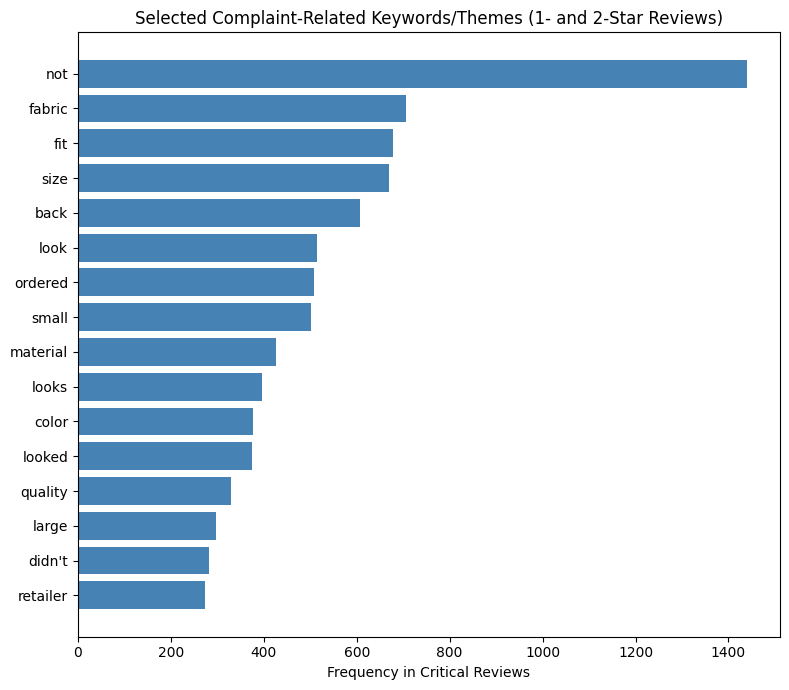

In [27]:
# ============================================================
# Keyword Frequency Visualization
# ============================================================

# Selected complaint-related keywords/themes, pulled directly from final_freq
# (frequencies are not hardcoded, so this reflects the actual Counter output)
selected_keywords = [
    "fit", "size", "small", "large",
    "fabric", "material", "quality",
    "color", "look", "looks", "looked",
    "ordered", "back", "retailer",
    "not", "didn't",
]

keyword_freqs = {word: final_freq[word] for word in selected_keywords}

# Sort for a readable horizontal bar chart (highest at top)
sorted_items = sorted(keyword_freqs.items(), key=lambda x: x[1])
labels = [item[0] for item in sorted_items]
values = [item[1] for item in sorted_items]

plt.figure(figsize=(8, 7))
plt.barh(labels, values, color="steelblue")
plt.xlabel("Frequency in Critical Reviews")
plt.title("Selected Complaint-Related Keywords/Themes (1- and 2-Star Reviews)")
plt.tight_layout()
plt.show()

### Phase 4 Summary

The critical-review text was analyzed using a transparent, frequency-based approach built with basic Python string manipulation and `collections.Counter`. The analysis progressed from an initial manual word-frequency check to punctuation normalization and two controlled refinement steps that removed clearly generic grammatical terms while retaining potentially informative vocabulary.

A dedicated **`get_complaint_keywords()`** function was then used to identify selected common complaint-related keywords from the final refined frequency results. This explicitly satisfies the assessment requirement for function-based complaint keyword identification while keeping the methodology simple and explainable.

The selected keywords indicate recurring discussion around **fit and sizing**, **fabric, material and quality**, **appearance and color**, and **order or product experience**. Some terms, such as `not`, `look`, and `back`, provide useful contextual signals but cannot be treated as definitive complaints based on frequency alone.

The analysis measures **word occurrences across the 2,370 critical reviews**, not the number of individual reviews or customers reporting each issue. The identified terms should therefore be interpreted as recurring vocabulary and potential complaint-related signals rather than direct complaint counts or automatically assigned themes.

No machine learning or advanced NLP techniques were used. The resulting keyword analysis provides a simple and reproducible view of the language present in critical customer feedback and completes the complaint-keyword analysis required by the assessment.


# Phase 5 - Selection of the 3 Most Critical Reviews

This phase selects three critical reviews that are most suitable for personalized customer outreach.

The selection process considers **rating severity, review detail, complaint clarity, and the amount of customer context available for a meaningful response**. Reviews rated 1 star are prioritized because they represent the highest level of rating severity within the defined critical-review group.

A data-supported **85-word minimum threshold** is first used to screen for sufficiently detailed reviews. The remaining candidates are then narrowed using a simple check for multiple concrete topic terms before the actual review content is manually inspected.

The final three reviews are selected through transparent manual assessment rather than a composite score, machine learning model, or advanced NLP method. The **Phase 4 keyword frequencies are not used as a selection score**.

The selected reviews will be carried forward to **Phase 6 - Generative AI Automated Outreach** for personalized response generation.


In [28]:
# ============================================================
# Establish Review Detail
# ============================================================

# Word count per review in critical_reviews (temporary analysis column, not stored permanently)
word_counts = critical_reviews["Review Text"].str.split().str.len()

print("Review word-count distribution (critical_reviews):")
print("Minimum:", word_counts.min())
print("Maximum:", word_counts.max())
print("Mean:", round(word_counts.mean(), 1))
print("Median:", word_counts.median())

print("\nPercentiles:")
for p in [25, 50, 75, 90, 95]:
    print(f"{p}th percentile:", word_counts.quantile(p / 100))

# Compare word count between 1-star and 2-star critical reviews
print("\nWord count by Rating:")
display(critical_reviews.groupby("Rating").apply(
    lambda g: g["Review Text"].str.split().str.len().describe()
))

# Inspect the longest reviews for context
print("\nTop 5 longest critical reviews (by word count):")
longest_idx = word_counts.sort_values(ascending=False).head(5).index
display(critical_reviews.loc[longest_idx, ["Rating", "Title", "Review Text"]].assign(
    word_count=word_counts.loc[longest_idx]
))

Review word-count distribution (critical_reviews):
Minimum: 3
Maximum: 111
Mean: 60.9
Median: 60.0

Percentiles:
25th percentile: 39.0
50th percentile: 60.0
75th percentile: 86.75
90th percentile: 97.0
95th percentile: 100.0

Word count by Rating:


Review Text,count,mean,std,min,25%,50%,75%,max
Rating,,,,,,,,
1,821.0,58.633374,27.324487,3.0,37.0,57.0,83.0,111.0
2,1549.0,62.056811,26.945238,6.0,40.0,62.0,88.0,110.0



Top 5 longest critical reviews (by word count):


,Rating,Title,Review Text,word_count
Review ID,,,,
6697,1,"odd fit, beautiful design but poor execution","i wanted to love this blouse so much. but try as i might, it just fit so oddly on me. i'm usuall...",111
7025,1,i thought this dress would...,i thought this dress would be a cute beach cover up so i was excited to order it but i was very ...,110
17330,2,fades! falling apart.,"within 2 washings the color faded to a not so black black, like a pair of pants that has been wa...",110
13631,2,couldn't send it back fast enough!,"unlike the other two reviews , i found this dress horrid. i ordered a xs since i am between that...",109
13646,2,too much fabric,as soon as i saw this dress i ordered it...i didn't want to miss out on it. i loved the look...t...,109


### Interpretation of Review Detail

The critical reviews have a median length of **60 words**, with the 75th percentile at approximately **87 words**. This indicates that reviews around or above this range generally provide more detailed customer context.

The word-count distribution provides a data-supported basis for selecting a minimum detail threshold before narrowing the candidate pool. Word count is used only as a **proxy for review detail**, not as a measure of complaint severity.


In [29]:
# ============================================================
# Compare Detail Thresholds
# ============================================================

# Compare a few plausible thresholds around the upper-quartile / 90th-percentile region
candidate_thresholds = [60, 75, 85, 90, 97]

print("Threshold comparison:")
for t in candidate_thresholds:
    pool = critical_reviews[word_counts >= t]
    one_star = (pool["Rating"] == 1).sum()
    two_star = (pool["Rating"] == 2).sum()
    print(f"Threshold >= {t} words: {len(pool)} reviews total ({one_star} one-star, {two_star} two-star)")

Threshold comparison:
Threshold >= 60 words: 1195 reviews total (388 one-star, 807 two-star)
Threshold >= 75 words: 839 reviews total (266 one-star, 573 two-star)
Threshold >= 85 words: 628 reviews total (199 one-star, 429 two-star)
Threshold >= 90 words: 533 reviews total (166 one-star, 367 two-star)
Threshold >= 97 words: 264 reviews total (76 one-star, 188 two-star)


### Interpretation of Detail Thresholds

The threshold comparison shows how progressively stricter word-count requirements reduce the available candidate pool. A threshold of **85 words** provides a practical balance: it is close to the upper-quartile region while retaining **628 detailed critical reviews**, including **199 one-star reviews**.

Therefore, **85 words is selected as the minimum detail threshold** for the next screening step. This threshold is used only to identify sufficiently detailed reviews and does not represent complaint severity.


In [30]:
# ============================================================
# Create the Candidate Pool
# ============================================================

# THRESHOLD will be set based on the Step 2 output
THRESHOLD = 85  

candidate_pool = critical_reviews[word_counts >= THRESHOLD].copy()
candidate_pool["Word Count"] = word_counts[word_counts >= THRESHOLD]

# Prioritize 1-star reviews first, then 2-star, longest detail first within each
candidate_pool = candidate_pool.sort_values(["Rating", "Word Count"], ascending=[True, False])

display_cols = ["Rating", "Title", "Review Text", "Word Count", "Product Recommended",
                 "Positive Feedback Count", "Division Name", "Department Name", "Class Name"]

print(f"Candidate pool size: {len(candidate_pool)} (1-star: {(candidate_pool['Rating']==1).sum()}, 2-star: {(candidate_pool['Rating']==2).sum()})")
display(candidate_pool[display_cols])

Candidate pool size: 628 (1-star: 199, 2-star: 429)


,Rating,Title,Review Text,Word Count,Product Recommended,Positive Feedback Count,Division Name,Department Name,Class Name
Review ID,,,,,,,,,
6697,1,"odd fit, beautiful design but poor execution","i wanted to love this blouse so much. but try as i might, it just fit so oddly on me. i'm usuall...",111,No,7,General,Tops,Knits
7025,1,i thought this dress would...,i thought this dress would be a cute beach cover up so i was excited to order it but i was very ...,110,No,0,General Petite,Intimate,Lounge
18856,1,disappointed,this dress has been in my inbox for a long time and when it went on sale i purchased it right aw...,108,No,1,General Petite,Dresses,Dresses
4297,1,great dress but not functional,"i loved this dress. it runs small (i'm normally a 2) so i had to get a 4. in the fitting room, t...",107,No,3,General,Dresses,Dresses
18276,1,weird fit,i loved the look of this blouse online. i really wanted a cute eyelet top for summer. the blouse...,107,No,1,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...
17903,2,not impressed,"i'm 5'4"" 120# , 34d. this dress did nothing for me. the seem on the side with the knot doesn't l...",85,No,13,General Petite,Dresses,Dresses
18190,2,yuck,i love jumpsuits - except for this one. the fabric is blah. it's between plastic and the materia...,85,No,0,General,Bottoms,Pants
18350,2,fit is unflattering,i wish i had read more of the reviews....but thought i would give it a try. the shirt doesn't se...,85,No,0,General,Tops,Blouses


### Interpretation of Candidate Pool

Applying the **85-word minimum threshold** produces **628 detailed critical reviews**, consisting of **199 one-star** and **429 two-star** reviews.

The candidate pool is ordered with **1-star reviews first**, reflecting their higher rating severity, and longer reviews first within each rating to make the subsequent manual inspection more efficient.


In [31]:
# ============================================================
# Narrow Candidates for Manual Inspection
# ============================================================

# One-star candidate pool (from Step 3 threshold)
one_star_pool = candidate_pool[candidate_pool["Rating"] == 1].copy()
two_star_pool = candidate_pool[candidate_pool["Rating"] == 2].copy()

# Simple, transparent proxy for "specific, detailed complaint": presence of concrete
# topic words the assignment itself names (fit, sizing, material, quality, appearance,
# functionality, ordering). This is a presence check, not a frequency score or ranking formula.
topic_terms = ["fit", "size", "sizing", "fabric", "material", "quality", "color",
               "look", "small", "large", "return", "order", "zipper", "seam", "stitch"]

def topic_hits(text):
    return sum(1 for term in topic_terms if term in text)

one_star_pool["Topic Mentions"] = one_star_pool["Review Text"].apply(topic_hits)
two_star_pool["Topic Mentions"] = two_star_pool["Review Text"].apply(topic_hits)

# Shortlist: require at least 2 topic-term mentions (i.e. more than one concrete aspect
# discussed, not just one passing word), then sort by Word Count as a simple, transparent
# tie-breaker (not a composite score — just ordering for readability)
one_star_shortlist = one_star_pool[one_star_pool["Topic Mentions"] >= 2].sort_values("Word Count", ascending=False).head(30)
two_star_shortlist = two_star_pool[two_star_pool["Topic Mentions"] >= 2].sort_values("Word Count", ascending=False).head(15)

display_cols = ["Rating", "Title", "Review Text", "Word Count", "Topic Mentions", "Product Recommended",
                 "Positive Feedback Count", "Division Name", "Department Name", "Class Name"]

print(f"One-star shortlist: {len(one_star_shortlist)} reviews")
display(one_star_shortlist[display_cols])

print(f"\nTwo-star shortlist: {len(two_star_shortlist)} reviews")
display(two_star_shortlist[display_cols])

One-star shortlist: 30 reviews


,Rating,Title,Review Text,Word Count,Topic Mentions,Product Recommended,Positive Feedback Count,Division Name,Department Name,Class Name
Review ID,,,,,,,,,,
6697,1,"odd fit, beautiful design but poor execution","i wanted to love this blouse so much. but try as i might, it just fit so oddly on me. i'm usuall...",111,3,No,7,General,Tops,Knits
7025,1,i thought this dress would...,i thought this dress would be a cute beach cover up so i was excited to order it but i was very ...,110,4,No,0,General Petite,Intimate,Lounge
18856,1,disappointed,this dress has been in my inbox for a long time and when it went on sale i purchased it right aw...,108,2,No,1,General Petite,Dresses,Dresses
4297,1,great dress but not functional,"i loved this dress. it runs small (i'm normally a 2) so i had to get a 4. in the fitting room, t...",107,3,No,3,General,Dresses,Dresses
18276,1,weird fit,i loved the look of this blouse online. i really wanted a cute eyelet top for summer. the blouse...,107,5,No,1,General,Tops,Blouses
19551,1,so disappointed!,the armholes on this dress are totally bizarre. i can't believe no one else has commented on the...,107,3,No,6,General Petite,Dresses,Dresses
2322,1,"too small, too complicated",i agree with the other reviewer who said there was too much hardware and such. this really does ...,106,2,No,0,General,Bottoms,Skirts
8080,1,horrible,"i cannot imagine this dress working in any size. i am a small, thin and average height woman (us...",106,3,No,2,General Petite,Dresses,Dresses
5467,1,"poorly made, static, and too tight.","1. i like a shorter jacket, but this one was poorly made and poorly fit. 2. the sleeves were way...",105,4,No,8,General Petite,Jackets,Jackets



Two-star shortlist: 15 reviews


,Rating,Title,Review Text,Word Count,Topic Mentions,Product Recommended,Positive Feedback Count,Division Name,Department Name,Class Name
Review ID,,,,,,,,,,
17330,2,fades! falling apart.,"within 2 washings the color faded to a not so black black, like a pair of pants that has been wa...",110,4,No,0,General,Bottoms,Pants
13646,2,too much fabric,as soon as i saw this dress i ordered it...i didn't want to miss out on it. i loved the look...t...,109,4,No,12,General,Dresses,Dresses
13631,2,couldn't send it back fast enough!,"unlike the other two reviews , i found this dress horrid. i ordered a xs since i am between that...",109,4,No,8,General,Dresses,Dresses
19958,2,so cute but design failure,i am usually a size o and ordered and xs ...due to the band in the center (not much give) it was...,108,4,No,14,Initmates,Intimate,Swim
12725,2,"great idea, but...","every single time i was in a store, this dress caught my eye. there was never a large or xl to t...",107,3,No,1,General Petite,Dresses,Dresses
12881,2,had to return,"i loved this dress and it fit perfectly. i did not have any issue with the camisole being tight,...",107,5,No,2,General Petite,Dresses,Dresses
16787,2,unflattering,"i really love the pattern and the look on the model, and i thought i would love it. i ordered on...",107,4,No,0,General,Dresses,Dresses
7929,2,wider and swingier than pictured,"this top looks so pretty on the model. however, the photo is deceiving as the bottom section is ...",106,4,No,5,General Petite,Tops,Knits
10195,2,how do i use my arms???,i loved the look of this dress online so i went to retailer to try it on. in the dressing room a...,106,2,No,1,General,Dresses,Dresses


### Methodology for Narrowing Candidates

To make manual inspection more manageable, the detailed candidate pool is narrowed using a simple content-based screening step.

A review must contain at least **two predefined topic terms** related to concrete product or customer-experience issues, such as fit, sizing, material, quality, appearance, returns, or product construction. This helps identify reviews that discuss more than one specific aspect of the experience.

The resulting shortlists are limited to the **30 longest one-star reviews** and **15 longest two-star reviews** meeting this condition. This is a screening step only; the final three reviews are selected by manually examining the actual review content.


In [32]:
# ============================================================
# Final Selection
# ============================================================

selected_ids = [6697, 5467, 21238]

final_three = candidate_pool.loc[
    candidate_pool.index.isin(selected_ids),
    ["Rating", "Title", "Review Text", "Word Count", "Product Recommended",
     "Positive Feedback Count", "Division Name", "Department Name", "Class Name"]
].sort_index()

display(final_three)

,Rating,Title,Review Text,Word Count,Product Recommended,Positive Feedback Count,Division Name,Department Name,Class Name
Review ID,,,,,,,,,
5467,1,"poorly made, static, and too tight.","1. i like a shorter jacket, but this one was poorly made and poorly fit. 2. the sleeves were way...",105,No,8,General Petite,Jackets,Jackets
6697,1,"odd fit, beautiful design but poor execution","i wanted to love this blouse so much. but try as i might, it just fit so oddly on me. i'm usuall...",111,No,7,General,Tops,Knits
21238,1,poor quality control,"i love the idea of this shirt, but the execution is absolutely horrible. i ordered online and wh...",101,No,3,General,Tops,Blouses


### Interpretation of Final Selection

Three reviews were selected for the final outreach stage: **Review IDs 6697, 5467, and 21238**.

All three are **1-star reviews**, exceed the **85-word detail threshold**, and contain specific information about the customer's product experience. Their detailed descriptions provide sufficient context for generating personalized responses in the next phase.


In [33]:
# ============================================================
# Validate Selected Reviews
# ============================================================

pd.set_option("display.max_colwidth", None)

for review_id in selected_ids:
    row = final_three.loc[review_id]
    print("=" * 100)
    print(f"Review ID: {review_id}")
    print(f"Rating: {row['Rating']}")
    print(f"Title: {row['Title']}")
    print(f"Word Count: {row['Word Count']}")
    print(f"Product Recommended: {row['Product Recommended']}")
    print(f"Positive Feedback Count: {row['Positive Feedback Count']}")
    print(f"Division: {row['Division Name']}")
    print(f"Department: {row['Department Name']}")
    print(f"Class: {row['Class Name']}")
    print("\nReview Text:")
    print(row["Review Text"])
    print("=" * 100)

Review ID: 6697
Rating: 1
Title: odd fit, beautiful design but poor execution
Word Count: 111
Product Recommended: No
Positive Feedback Count: 7
Division: General
Department: Tops
Class: Knits

Review Text:
i wanted to love this blouse so much. but try as i might, it just fit so oddly on me. i'm usually a petite s so i purchased the xs in brown. first. the color was more gray-brown but it was still ok. but second, the fit was off. maybe i just got a bad one, but the center of the blouse was so offset, that the slit in the front laid so far to the left and the v-neck was so low that you could see my bra - there was no adjusting i could do to fix it. the material has a lovely soft silky feel to it an
Review ID: 5467
Rating: 1
Title: poorly made, static, and too tight.
Word Count: 105
Product Recommended: No
Positive Feedback Count: 8
Division: General Petite
Department: Jackets
Class: Jackets

Review Text:
1. i like a shorter jacket, but this one was poorly made and poorly fit. 2. the sl

### Phase 5 Summary

A transparent screening and manual-selection process was used to identify three reviews suitable for personalized customer outreach.

The **2,370 critical reviews** were first assessed by review length to establish a practical detail threshold. An **85-word minimum** was selected, producing a candidate pool of **628 reviews**, including **199 one-star** and **429 two-star** reviews. One-star reviews were prioritized because they represent the highest rating severity within the critical-review definition.

The candidate pool was then narrowed using a simple content-based check for reviews mentioning at least two concrete product or customer-experience topics. This created manageable shortlists for manual inspection without introducing a composite score, machine learning model, or advanced NLP method.

The final selection consists of **Review IDs 6697, 5467, and 21238**. All three are **1-star reviews exceeding the 85-word threshold** and provide specific product-related context that can support personalized customer responses.

The selected reviews will now be used as the input for **Phase 6 - Generative AI Automated Outreach**, where the actual review content and available context will be used to generate individualized, empathetic responses.


# Phase 6 - Generative AI Automated Outreach

This phase uses Generative AI to create personalized customer-support emails for the three critical reviews selected in Phase 5.

The **Gemini 3.5 Flash-Lite** model is used through Google's `google-genai` Python SDK. The API credential is kept outside the notebook and loaded through the `GEMINI_API_KEY` environment variable rather than being hard-coded.

A reusable prompt template and Python function are used to apply the same response-generation process consistently across all three reviews. The prompt instructs the model to acknowledge the specific issues described by each customer, respond empathetically, and use only information available in the supplied review and product context.

The generated responses are also constrained to avoid unsupported claims such as refunds, replacements, compensation, policies, guarantees, or actions already taken. Because the source reviews contain text that ends abruptly, the model is explicitly instructed not to reconstruct or infer missing content.

The final responses are reviewed against the assessment requirements for **personalization, relevance, empathy, conciseness, and factual grounding**.


In [34]:
# ============================================================
# API Setup & Secure Credential Handling
# ============================================================

# Run once if google-genai is not already installed
# !pip install google-genai
# !pip install python-dotenv

import os
from dotenv import load_dotenv
from google import genai

load_dotenv()

api_key = os.environ.get("GEMINI_API_KEY")
assert api_key, "GEMINI_API_KEY environment variable not found. Set it before running this cell."

client = genai.Client(api_key=api_key)


In [35]:
# ============================================================
# API Connection Test
# ============================================================

# Small connection/generation test
test_response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents="Reply with exactly: Connection successful."
)
print(test_response.text)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Connection successful.


### API Connection Test

The API connection was tested with a small generation request before processing the selected customer reviews. A successful response confirms that the Gemini client is configured correctly and can communicate with the selected model.

This confirms that the environment is ready for the customer-support response generation step.


In [36]:
# ============================================================
# Customer-Support Prompt Template
# ============================================================

PROMPT_TEMPLATE = """You are a professional customer-support representative for a women's clothing retailer.

A customer left the following review:

Title: {title}
Rating: {rating} out of 5 stars
Product category: {department} - {class_name}
Review: "{review_text}"

Write a short, empathetic customer-support email replying to this review.

Rules:
- Acknowledge the specific issue(s) the customer actually described.
- Personalize the reply using real details from the review (e.g. fit, fabric, sizing, quality, appearance) - do not use generic phrases that could apply to any review.
- Apologize sincerely for their experience.
- Use ONLY information present in the review above. Do not invent product facts, policies, refunds, replacements, compensation, or guarantees.
- Do not state that any specific action has already been taken.
- The review text may be cut off; do not guess or reconstruct what the missing portion might say.
- Keep the email concise (roughly 80-120 words).
- Sound like a genuine, warm human email, not a generic AI-generated message.
- Sign off as "Customer Support Team".

Write only the email, with no extra commentary."""

### Customer-Support Prompt Methodology

A reusable prompt template is used to keep the Generative AI responses consistent while allowing each email to be personalized from the selected review.

The prompt requires Gemini to acknowledge the **specific issues described by the customer**, use relevant review details, maintain an empathetic tone, and keep the response concise. It also restricts the model to information actually provided in the review and prevents unsupported claims about refunds, replacements, compensation, policies, guarantees, or actions already taken.

Because some source reviews end abruptly, the prompt explicitly instructs the model **not to reconstruct or infer missing review content**. This helps keep the generated responses grounded in the available dataset.


In [37]:
# ============================================================
# Build the Response Generation Function
# ============================================================

def generate_support_email(review_id, rating, title, review_text, department, class_name):
    """
    Build a personalized prompt from the given review details, send it to Gemini,
    and return the generated customer-support email text.
    """
    prompt = PROMPT_TEMPLATE.format(
        title=title,
        rating=rating,
        department=department,
        class_name=class_name,
        review_text=review_text
    )

    try:
        response = client.models.generate_content(
            model="gemini-3.5-flash-lite",
            contents=prompt
        )
        return response.text
    except Exception as e:
        print(f"API call failed for Review ID {review_id}: {e}")
        return None

### Response Generation Function

A reusable `generate_support_email()` function was created to construct the prompt from each review's details, send it to Gemini, and return the generated email.

The function keeps the API logic separate from the review-specific data, allowing the same generation process to be applied consistently to the test review and the final three selected reviews. Basic exception handling is included so that an API failure is reported for the relevant Review ID rather than stopping the entire workflow.


In [36]:
# ============================================================
# Test Response Generation
# ============================================================

test_email = generate_support_email(
    review_id=6697,
    rating=1,
    title="odd fit, beautiful design but poor execution",
    review_text=(
        "i wanted to love this blouse so much. but try as i might, it just fit so "
        "oddly on me. i'm usually a petite s so i purchased the xs in brown. first. "
        "the color was more gray-brown but it was still ok. but second, the fit was "
        "off. maybe i just got a bad one, but the center of the blouse was so "
        "offset, that the slit in the front laid so far to the left and the v-neck "
        "was so low that you could see my bra - there was no adjusting i could do "
        "to fix it. the material has a lovely soft silky feel to it an"
    ),
    department="Tops",
    class_name="Knits"
)

print(test_email)

Subject: Regarding your recent review of our brown knit blouse

Dear Customer,

Thank you for sharing your feedback with us. I am so sorry to hear that you had such a frustrating experience with the brown knit blouse, especially since you were hoping to love it as a petite small ordering the XS. 

It is completely disappointing that the color turned out to be more gray-brown than expected, and that the construction issues—such as the heavily offset center, the misplaced front slit, and the excessively low V-neck revealing your bra—made the blouse unwearable despite its lovely, soft, silky fabric. 

We truly appreciate you bringing these specific quality and sizing concerns to our attention. 

Warmly,

Customer Support Team


### Test Response Validation

Review ID **6697** was used to test the complete response-generation workflow before processing all three selected reviews.

The test confirms that the prompt template, response-generation function, API connection, and review-specific inputs work together successfully. The generated email can then be reviewed for **specificity, personalization, empathy, and adherence to the supplied review content** before generating the final three responses.


In [37]:
# ============================================================
# Generate Responses for the 3 Selected Reviews
# ============================================================

selected_reviews = [
    {
        "review_id": 6697,
        "rating": 1,
        "title": "odd fit, beautiful design but poor execution",
        "department": "Tops",
        "class_name": "Knits",
        "review_text": (
            "i wanted to love this blouse so much. but try as i might, it just fit so "
            "oddly on me. i'm usually a petite s so i purchased the xs in brown. first. "
            "the color was more gray-brown but it was still ok. but second, the fit was "
            "off. maybe i just got a bad one, but the center of the blouse was so "
            "offset, that the slit in the front laid so far to the left and the v-neck "
            "was so low that you could see my bra - there was no adjusting i could do "
            "to fix it. the material has a lovely soft silky feel to it an"
        ),
    },
    {
        "review_id": 5467,
        "rating": 1,
        "title": "poorly made, static, and too tight.",
        "department": "Jackets",
        "class_name": "Jackets",
        "review_text": (
            "1. i like a shorter jacket, but this one was poorly made and poorly fit. "
            "2. the sleeves were way too tight. i'm a size 10 or 12, and the large "
            "which would be a 14 had tight sleeves that wrinkled up my arms, and the "
            "hem of the sleeve turned inside out. 3. i ordered both a medium (size 10) "
            "and a large (size 14) , and neither hung right. the m too tight, and the "
            "large too loose in the body and too tight in the sleeves. 4. very "
            "polyester with lots of static. 5. cute idea, but not very good in pe"
        ),
    },
    {
        "review_id": 21238,
        "rating": 1,
        "title": "poor quality control",
        "department": "Tops",
        "class_name": "Blouses",
        "review_text": (
            "i love the idea of this shirt, but the execution is absolutely horrible. "
            "i ordered online and what i received is just a mess. the stitching at the "
            "bottom has big globs of black thread. not just a few hanging off, but "
            "literally big clumps. a large portion of the stitching on the whole shirt "
            "looks like it should be on the underside of the shirt as the where the "
            "thread is tied off is on the outside!! the fit is just as big a mess. "
            "i always have to buy a large in fitted shirts because i have very br"
        ),
    },
]

generated_emails = []
for review in selected_reviews:
    email_text = generate_support_email(
        review_id=review["review_id"],
        rating=review["rating"],
        title=review["title"],
        review_text=review["review_text"],
        department=review["department"],
        class_name=review["class_name"]
    )
    generated_emails.append({**review, "generated_email": email_text})

for item in generated_emails:
    print(f"Review ID: {item['review_id']}")
    print(f"Title: {item['title']}")
    print("Generated Email:")
    print(item["generated_email"])
    print("-" * 80)

Review ID: 6697
Title: odd fit, beautiful design but poor execution
Generated Email:
Subject: Regarding your recent review of our brown knit blouse

Dear Customer,

Thank you so much for taking the time to share your honest feedback about the brown knit blouse. I am truly sorry to hear that it did not fit you properly and that your experience fell short of expectations. 

It is disappointing that the color turned out to be more gray-brown, and I am especially sorry that the center of the blouse was offset, causing the front slit to lay too far to the left and the V-neck to sit too low to wear comfortably with your bra. 

We are glad to hear that you appreciated the lovely, soft silky feel of the material, but I completely understand how frustrating it is when the execution of the fit makes the top unwearable, even in the extra-small size. 

Warmly,

Customer Support Team
--------------------------------------------------------------------------------
Review ID: 5467
Title: poorly made,

### Validate Generated Responses

The generated responses were reviewed against the requirements of the Generative AI component: **specificity, personalization, empathy, conciseness, factual grounding, and avoidance of unsupported commitments**.

| Validation Criterion                   | Assessment                                                                                               |
| -------------------------------------- | -------------------------------------------------------------------------------------------------------- |
| Specific complaint addressed           | ✓ Each response addresses the customer's actual concerns                                                 |
| Personalized to the review             | ✓ Product details, fit issues, sizing, material, colour, or quality issues are referenced where relevant |
| Empathetic and apologetic              | ✓ Responses acknowledge the customer's negative experience and apologize appropriately                   |
| Concise customer-support style         | ✓ Responses remain focused and suitable for customer outreach                                            |
| Uses relevant review details           | ✓ Details are drawn from the supplied review text and product context                                    |
| No unsupported refunds or compensation | ✓ No refunds, replacements, compensation, or guarantees are promised                                     |
| No unsupported company actions         | ✓ No specific action is claimed to have already been taken                                               |
| Professional outreach tone             | ✓ All responses maintain a professional and customer-support-oriented tone                               |

The test response for **Review ID 6697** successfully validated the complete prompt and response-generation workflow before the three final responses were generated. The final responses for **Review IDs 6697, 5467, and 21238** each address the specific issues described in their respective reviews rather than using a generic apology.

A small amount of natural-language interpretation is present in the generated responses, but the responses remain grounded in the supplied review content. No material unsupported claim, compensation promise, or company action was introduced.

**Data note:** Some source review texts in the dataset end abruptly. The responses were generated using only the text available in the dataset, and the missing portions were not reconstructed or inferred. This is particularly relevant for the three selected reviews, whose source text is incomplete at the end.


### Phase 6 Summary

The three critical reviews selected in Phase 5 were processed using **Generative AI to produce personalized customer-support responses**. The workflow used the **Gemini 3.5 Flash-Lite** model through Google's `google-genai` Python SDK, with the API credential securely loaded through the `GEMINI_API_KEY` environment variable rather than being hard-coded in the notebook.

A reusable prompt template and response-generation function were used to apply the same generation process consistently across the selected reviews while incorporating review-specific details. The prompt emphasized **specific complaint acknowledgement, empathy, concise communication, factual grounding, and avoidance of unsupported commitments** such as refunds, replacements, compensation, guarantees, or actions already taken.

The final responses addressed the individual issues described in the selected reviews, including **fit and construction problems, sizing and sleeve issues, fabric/static concerns, and product quality-control defects**. The generated responses were reviewed against the assessment requirements and remained grounded in the information available in the source data.

Because the selected source reviews contain text that ends abruptly, the Generative AI workflow deliberately used only the available review content and did not attempt to reconstruct the missing portions. This preserves the factual limitations of the original dataset rather than introducing unsupported customer details.

With the three personalized responses generated and validated, the core **customer feedback analysis and automated response workflow is complete**. The results from Phases 1-6 now provide the basis for the final notebook conclusion and overall assessment deliverables.


# 🎯 Conclusion - Key Findings & Outcome

This project developed an end-to-end workflow for transforming raw customer review data into actionable customer-support responses.

The dataset was first cleaned and prepared while preserving usable customer feedback and maintaining record-level traceability. A transparent rule-based approach then identified **1- and 2-star reviews as critical**, resulting in a focused subset of **2,370 critical reviews** from the analysis-ready dataset.

Frequency-based text analysis identified recurring discussion around **fit and sizing, fabric and material quality, appearance and color, and order or product experience**. These findings were treated as recurring vocabulary and potential complaint signals rather than automatic complaint classifications, keeping the analysis aligned with the limitations of the methodology.

A structured screening and manual-selection process was then used to identify **three detailed 1-star reviews** suitable for personalized outreach. These reviews provided sufficient customer and product context to support individualized responses.

Finally, **Generative AI using Gemini 3.5 Flash-Lite** was used to generate concise, empathetic customer-support emails based only on the information available in the selected reviews. The generated responses were validated for specificity, personalization, factual grounding, and appropriate customer-support tone.

Overall, the project demonstrates how **Python-based data preparation and transparent rule-based analysis can be combined with Generative AI to move from customer feedback analysis to practical, personalized customer engagement**, while keeping the core analytical decisions explainable and reproducible.


In [39]:
# ============================================================
# PROJECT SNAPSHOT
# ============================================================

print("📊 PROJECT SNAPSHOT")
print("=" * 45)

print(f"Analysis-ready reviews:          {len(df_analysis):,}")
print(f"Critical reviews (1–2 stars):    {len(critical_reviews):,}")
print(f"Critical review percentage:      {critical_pct:.2f}%")
print(f"1-star critical reviews:         {one_star:,}")
print(f"2-star critical reviews:         {two_star:,}")
print(f"Reviews selected for outreach:   {len(selected_ids)}")
print(f"GenAI model:                     Gemini 3.5 Flash-Lite")

print("=" * 45)

📊 PROJECT SNAPSHOT
Analysis-ready reviews:          22,628
Critical reviews (1–2 stars):    2,370
Critical review percentage:      10.47%
1-star critical reviews:         76
2-star critical reviews:         188
Reviews selected for outreach:   3
GenAI model:                     Gemini 3.5 Flash-Lite
